# Manual Feed-Forward Network: Optimiser Comparison on MNIST

**Goal:** implement a feed-forward neural network's forward and backward pass by hand (no autograd shortcuts) and compare three optimisers.
**Dataset:** MNIST handwritten digits.
**Approach:** derive and implement the gradients manually, then train with plain SGD, SGD with momentum, and AdaGrad.
**Headline result:** SGD with momentum reached the best test accuracy, 98.05%, versus 97.20% (plain SGD) and 96.53% (AdaGrad). See `README.md` and `../../docs/RESULTS.md`.

*Built as part of Monash University FIT5215 Deep Learning (2026).*


Author: Rahul Bhatt

# Deep Neural Networks: Manual Feed-Forward Network and Optimisers (MNIST)

## Part 1: Theory and Knowledge Questions

This part covers theoretical and applied questions on activation functions, forward and backward propagation, and a manual implementation of a feed-forward neural network trained on MNIST.

## Activation Functions: ELU and GELU

This section derives the output range and derivative of the ELU and GELU activation functions, and plots each function alongside its derivative.

### **(a) ELU**

For ELU with $\alpha = 0.1$, I took the piecewise definition and looked at the limits.

**Output range.** If $x > 0$, ELU$(x)=x$, so the positive side is unbounded. If $x \le 0$, ELU$(x)=0.1(e^x-1)$. As $x\to-\infty$, $e^x\to 0$, so ELU approaches $-0.1$ from above. At $x=0$, ELU$(0)=0$. So the range I get is $(-0.1,\infty)$.

**Derivative (with steps).**
- Case $x \le 0$:
  $$\frac{d}{dx}\big[0.1(e^x-1)\big] = 0.1\cdot e^x.$$
- Case $x > 0$:
  $$\frac{d}{dx}[x] = 1.$$
Putting those together:
$$\frac{d}{dx}\text{ELU}(x) = \begin{cases} 0.1 e^x & \text{if } x \le 0 \\ 1 & \text{if } x > 0 \end{cases}$$

I plotted ELU and this derivative in the next cell.

### **(b) GELU**

GELU is defined as $\text{GELU}(x)=x\Phi(x)$, where $\Phi$ is the standard normal CDF.

**Output range.** Because $\Phi(x)\in(0,1)$ and $x$ can be negative, the product can go slightly below zero. From the plot (and the known minimum of GELU), the smallest value is about $-0.17$. As $x\to\infty$, GELU$(x)\to\infty$. So the range I use is approximately $(-0.17,\infty)$, not $(0,\infty)$.

**Derivative (with steps).** I used the product rule with $\Phi'(x)=\phi(x)$ (standard normal PDF):
$$\frac{d}{dx}\text{GELU}(x) = \Phi(x)\cdot 1 + x\cdot\phi(x) = \Phi(x) + x\phi(x).$$

I plotted GELU and this derivative together with ELU below.


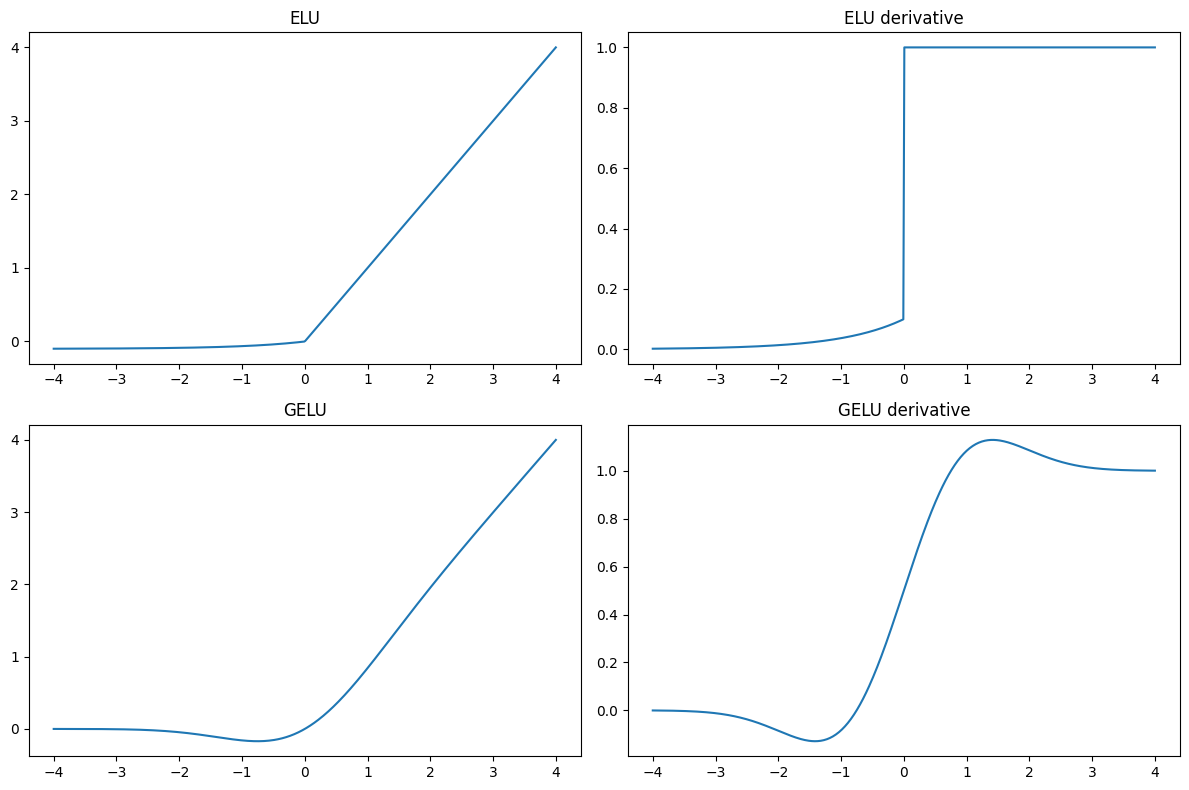

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

x = np.linspace(-4, 4, 500)
alpha = 0.1
elu = np.where(x > 0, x, alpha * (np.exp(x) - 1))
elu_deriv = np.where(x > 0, 1.0, alpha * np.exp(x))
phi = norm.cdf(x)
gelu = x * phi
gelu_deriv = phi + x * norm.pdf(x)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].plot(x, elu); axes[0,0].set_title('ELU')
axes[0,1].plot(x, elu_deriv); axes[0,1].set_title('ELU derivative')
axes[1,0].plot(x, gelu); axes[1,0].set_title('GELU')
axes[1,1].plot(x, gelu_deriv); axes[1,1].set_title('GELU derivative')
plt.tight_layout(); plt.show()


## Forward Pass Example: ReLU Feed-Forward Network

This section works through a numerical example of a feed-forward network with ReLU activations, using the data point and ground-truth label shown in the figure below.

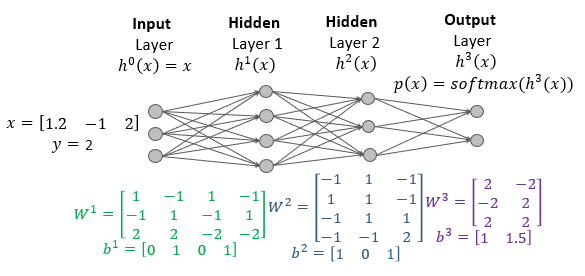

This computes the latent representations $h^1(x)$ and $h^2(x)$, the logits $h^3(x)$, the predicted probabilities $p(x)$, and the predicted label $\widehat{y}$, along with the cross-entropy loss, and discusses why the cross-entropy loss is always non-negative and when it equals zero.

### Worked example: forward pass, prediction, and loss

I used $x=[1.2,-1,2]$ and $y=2$, with ReLU after each linear layer, then softmax for the probabilities. Below I write the formula I used and the number I got for each part. (I also checked the arithmetic in the next code cell.)

**(a) Latent $h^1(x)$**
$$h^1(x)=\mathrm{ReLU}(xW_1+b_1)$$
I got $h^1(x)=[6.2,\ 2.8,\ 0,\ 0]$.

**(b) Latent $h^2(x)$**
$$h^2(x)=\mathrm{ReLU}(h^1(x)W_2+b_2)$$
I got $h^2(x)=[0,\ 9,\ 0]$.

**(c) Logit $h^3(x)$**
$$h^3(x)=h^2(x)W_3+b_3$$
I got $h^3(x)=[-17,\ 19.5]$.

**(d) Prediction probabilities $p(x)$**
$$p(x)=\mathrm{softmax}(h^3(x)),\quad p_i=\frac{e^{h^3_i}}{\sum_j e^{h^3_j}}$$
I got $p(x)\approx[1.41\times 10^{-16},\ 1.0]$.

**(e) Predicted label $\hat{y}$**
$$\hat{y}=\arg\max_i p_i(x)$$
I got $\hat{y}=2$. Since the ground-truth label is also $y=2$, this is a **correct** prediction.

**(f) Cross-entropy at $(x,y)$**
$$\mathrm{CE}(1_y,p(x))=-\log p_y(x)=-\log p_2(x)$$
Because $p_2\approx 1$, I get $\mathrm{CE}\approx 0$ (the code may print a tiny float like $-0.0$).

**(g) Why CE is always $\ge 0$, and when it is $0$ (general $M$ classes)**
For a general pair $(x,y)$ and an $M$-class network (e.g. $M=4$), the one-hot target $1_y$ has a $1$ only in position $y$, so
$$\mathrm{CE}(1_y,p(x))=-\sum_{m=1}^{M} 1_y[m]\log p_m(x)=-\log p_y(x).$$
Softmax probabilities satisfy $0 < p_y(x)\le 1$, so $-\log p_y(x)\ge 0$. I only get $\mathrm{CE}=0$ when $p_y(x)=1$ (the model puts all probability on the true class). That argument does not depend on the particular $x$ or on $M=2$ vs $M=4$; it holds for any feed-forward classifier with softmax + CE.

In [2]:
import torch, torch.nn.functional as F
x = torch.tensor([1.2, -1.0, 2.0])
W1 = torch.tensor([[1.,-1.,1.,-1.],[-1.,1.,-1.,1.],[2.,2.,-2.,-2.]])
b1 = torch.tensor([0.,1.,0.,1.])
W2 = torch.tensor([[-1.,1.,-1.],[1.,1.,-1.],[-1.,1.,1.],[-1.,-1.,2.]])
b2 = torch.tensor([1.,0.,1.])
W3 = torch.tensor([[2.,-2.],[-2.,2.],[2.,2.]])
b3 = torch.tensor([1.,1.5])
h1 = F.relu(x @ W1 + b1)
h2 = F.relu(h1 @ W2 + b2)
h3 = h2 @ W3 + b3
p = F.softmax(h3, dim=0)
print('h1', h1.tolist(), 'h2', h2.tolist(), 'h3', h3.tolist(), 'p', p.tolist())
print('pred', int(p.argmax())+1, 'CE', (-torch.log(p[1])).item())


h1 [6.199999809265137, 2.799999952316284, 0.0, 0.0] h2 [0.0, 9.0, 0.0] h3 [-17.0, 19.5] p [1.406861638989697e-16, 1.0]
pred 2 CE -0.0


## Implementation Options

This section offered a choice between performing one forward/backward pass and SGD update by hand for a single mini-batch, or manually implementing a feed-forward network trained on a real dataset.

**My approach:** I implemented **Option 2** — a manual feed-forward network on MNIST. The Option 1 cells below are kept as additional worked examples of the forward/backward pass and SGD update by hand.

## Worked Example: Manual Forward/Backward Pass and SGD Update

This section works through a small $3\rightarrow5(\text{ELU})\rightarrow3$ feed-forward network by hand, with weights generated from the author's student ID, as shown in the figure below.

The following sub-questions use the mini-batch $X$ and labels $Y$ shown above to work through forward propagation, backward propagation, and an SGD update by hand.

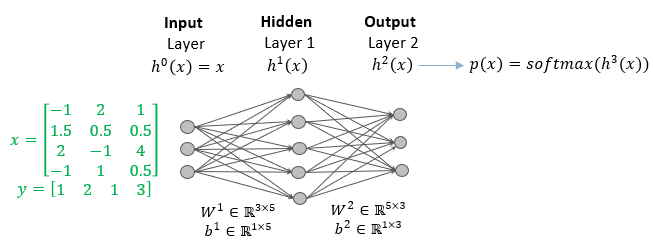

In [3]:
import torch
student_id = 00000000           #insert your student id here for example 1234
torch.manual_seed(student_id)

In [4]:
import torch
student_id = 00000000
torch.manual_seed(student_id)
W1 = torch.randn(3, 5); b1 = torch.randn(5)
W2 = torch.randn(5, 3); b2 = torch.randn(3)
X = torch.tensor([[-1.,2.,1.],[1.5,0.5,0.5],[2.,-1.,4.],[-1.,1.,0.5]])
Y = torch.tensor([1,2,1,3])
alpha = 0.1

def elu(x, alpha=0.1):
    return torch.where(x>0, x, alpha*(torch.exp(x)-1))
def elu_deriv(x, alpha=0.1):
    return torch.where(x>0, torch.ones_like(x), alpha*torch.exp(x))
print('W1', W1.shape, 'X', X.shape, 'Y', Y.tolist())


W1 torch.Size([3, 5]) X torch.Size([4, 3]) Y [1, 2, 1, 3]


### Forward propagation

This computes the pre-activation values $\bar{h}^1(x)$ of the first hidden layer.

In [5]:
h1_bar = X @ W1 + b1
print('(a) h1_bar[0]:', h1_bar[0].tolist())


(a) h1_bar[0]: [-3.5662989616394043, -0.36137282848358154, -3.2131776809692383, -3.5881948471069336, 2.548591375350952]


This computes the post-activation values $h^1(x)$ of the first hidden layer.

In [6]:
h1 = elu(h1_bar)
print('(b) h1[0]:', h1[0].tolist())


(b) h1[0]: [-0.09717398136854172, -0.030328083783388138, -0.09597714245319366, -0.09723518043756485, 2.548591375350952]


This computes the predicted label $\widehat{y}$ for the mini-batch.

In [7]:
logits = h1 @ W2 + b2
probs = torch.softmax(logits, dim=1)
print('(c) pred:', (probs.argmax(1)+1).tolist())


(c) pred: [2, 1, 2, 2]


This computes the cross-entropy loss incurred by the mini-batch.

In [8]:
Y0 = Y - 1
loss = torch.nn.functional.cross_entropy(logits, Y0)
print('(d) CE loss:', loss.item())


(d) CE loss: 3.299374580383301


### Backward propagation

This derives the gradients $\partial l/\partial h^2$, $\partial l/\partial W^2$, and $\partial l/\partial b^2$.

In [9]:
N = X.shape[0]
grad_logits = probs.clone(); grad_logits[torch.arange(N), Y0] -= 1; grad_logits /= N
grad_W2 = h1.T @ grad_logits; grad_b2 = grad_logits.sum(0)
print('(e) grad_W2:\n', grad_W2)


(e) grad_W2:
 tensor([[ 1.3682e-02, -3.1376e-02,  1.7694e-02],
        [-7.7342e-04, -8.1765e-03,  8.9500e-03],
        [ 8.4153e-01, -8.6548e-01,  2.3952e-02],
        [-2.0174e-01,  9.9555e-02,  1.0219e-01],
        [-5.5682e-01,  8.8985e-01, -3.3304e-01]])


This derives the gradients $\partial l/\partial h^1$, $\partial l/\partial \bar{h}^1$, $\partial l/\partial W^1$, and $\partial l/\partial b^1$.

In [10]:
grad_h1 = grad_logits @ W2.T
grad_h1_bar = grad_h1 * elu_deriv(h1_bar)
grad_W1 = X.T @ grad_h1_bar; grad_b1 = grad_h1_bar.sum(0)
print('(f) grad_W1 row0:', grad_W1[0].tolist())


(f) grad_W1 row0: [-0.008562305942177773, 0.027173565700650215, 0.5796736478805542, -0.02894977107644081, -0.6725128293037415]


### SGD update

This applies one SGD update, with learning rate $\eta=0.01$, to the model parameters $W^1, b^1, W^2, b^2$.

In [11]:
lr = 0.01
W2 -= lr*grad_W2; b2 -= lr*grad_b2; W1 -= lr*grad_W1; b1 -= lr*grad_b1
print('(g) updated W2:\n', W2)


(g) updated W2:
 tensor([[-2.3066,  0.8776,  0.4721],
        [-1.0781, -1.1044,  1.2258],
        [ 0.7509, -0.8732, -0.3853],
        [-0.8186, -0.4458, -0.6889],
        [-0.6039,  0.7005, -0.8940]])


## Manual Feed-Forward Network on MNIST

In [12]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

This section implements a feed-forward neural network manually using PyTorch's autograd, then trains it on the MNIST dataset.

We first download the `MNIST` dataset and preprocess it.

In [13]:
transform = transforms.Compose([
    transforms.ToTensor(),  # Convert the image to a tensor with shape [C, H, W]
    transforms.Normalize((0.5,), (0.5,)),  # Normalize to [-1, 1]
    transforms.Lambda(lambda x: x.view(28*28)) # Flatten the tensor to shape [-1,HW]
])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

torch.Size([60000, 28, 28]) torch.Size([60000])
torch.Size([10000, 28, 28]) torch.Size([10000])


Each data point has dimension `[28,28]`. We need to flatten it to a vector to input to our FFN.

In [14]:
train_dataset.data = train_data.data.reshape(-1, 28*28)
test_dataset.data = test_data.data.reshape(-1, 28*28)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

torch.Size([60000, 784]) torch.Size([60000])
torch.Size([10000, 784]) torch.Size([10000])


We split the train and test sets into many mini-batches of 64.

In [15]:
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

### Building the feed-forward network

This implements the `MyLinear` layer class, including its weight matrix and bias parameters.

In [16]:
class MyLinear(torch.nn.Module):
  def __init__(self, input_size, output_size):
    """
    input_size: the size of the input
    output_size: the size of the output
    """
    super().__init__()
    self.W = torch.nn.Parameter(torch.randn(input_size, output_size) * 0.01)
    self.b = torch.nn.Parameter(torch.zeros(output_size))

  def forward(self, x): #x is a mini-batch
    return x @ self.W + self.b


This implements the `MyFFN` class, which assembles the linear layers into a full feed-forward network.

In [17]:
class MyFFN(torch.nn.Module):
  def __init__(self, input_size, num_classes, hidden_sizes, act = torch.nn.ReLU()):
    super(MyFFN, self).__init__()
    self.input_size = input_size
    self.num_classes = num_classes
    self.act = act() if isinstance(act, type) else act
    self.hidden_sizes = hidden_sizes
    self.num_layers = len(hidden_sizes) + 1
    self.layers = torch.nn.ModuleList()
    self.velocity = None
    self.ada_cache = None

  def create_FFN(self):
    sizes = [self.input_size] + self.hidden_sizes + [self.num_classes]
    self.layers = torch.nn.ModuleList([MyLinear(sizes[i], sizes[i+1]) for i in range(len(sizes)-1)])

  def forward(self, x):
    h = x
    for i, layer in enumerate(self.layers):
      h = layer(h)
      if i < len(self.layers) - 1:
        h = self.act(h)
    return h

  def compute_loss(self, x, y):
    return torch.nn.functional.cross_entropy(self.forward(x), y)

  def update_SGD(self, x, y, learning_rate = 0.01):
    loss = self.compute_loss(x, y)
    loss.backward()
    with torch.no_grad():
      for p in self.parameters():
        if p.grad is not None:
          p -= learning_rate * p.grad
          p.grad.zero_()
    return loss.item()

  def update_SGDwithMomentum(self, x, y, learning_rate = 0.01, momentum = 0.9):
    loss = self.compute_loss(x, y)
    loss.backward()
    if self.velocity is None:
      self.velocity = [torch.zeros_like(p) for p in self.parameters()]
    with torch.no_grad():
      for i, p in enumerate(self.parameters()):
        if p.grad is None: continue
        self.velocity[i] = momentum * self.velocity[i] + p.grad
        p -= learning_rate * self.velocity[i]
        p.grad.zero_()
    return loss.item()

  def update_AdaGrad(self, x, y, learning_rate = 0.01):
    loss = self.compute_loss(x, y)
    loss.backward()
    if self.ada_cache is None:
      self.ada_cache = [torch.zeros_like(p) for p in self.parameters()]
    with torch.no_grad():
      for i, p in enumerate(self.parameters()):
        if p.grad is None: continue
        self.ada_cache[i] += p.grad ** 2
        p -= learning_rate * p.grad / (torch.sqrt(self.ada_cache[i]) + 1e-8)
        p.grad.zero_()
    return loss.item()

  def __repr__(self):
    return f"MyFFN(layers={len(self.layers)}, hidden={self.hidden_sizes})"


In [18]:
myFFN = MyFFN(input_size = 28*28, num_classes = 10, hidden_sizes = [100, 100], act = torch.nn.ReLU)
myFFN.create_FFN()
print(myFFN)

MyFFN(layers=3, hidden=[100, 100])


This implements a function to evaluate the model's accuracy on a given data loader.

In [19]:
def compute_acc(model, data_loader):
  """
  This function computes the accuracy of the model on a data loader
  """
  model.eval()
  correct, total = 0, 0
  with torch.no_grad():
    for X, y in data_loader:
      X = X.view(X.size(0), -1)
      pred = model(X).argmax(1)
      correct += (pred == y).sum().item()
      total += y.size(0)
  model.train()
  return correct / total


This implements a function to evaluate the model's loss on a given data loader.

In [20]:
def compute_loss(model, data_loader):
  """
  This function computes the loss of the model on a data loader
  """
  model.eval()
  total_loss, total = 0.0, 0
  with torch.no_grad():
    for X, y in data_loader:
      X = X.view(X.size(0), -1)
      loss = model.compute_loss(X, y)
      total_loss += loss.item() * X.size(0)
      total += X.size(0)
  model.train()
  return total_loss / total


Train on the `MNIST` data with 50 epochs using `updateSGD`.

In [21]:
num_epochs = 50
for epoch in range(num_epochs):
    for i, (x, y) in enumerate(train_loader):
      x = x.view(x.size(0), -1)
      myFFN.update_SGD(x, y, learning_rate = 0.01)
    train_acc = compute_acc(myFFN, train_loader)
    train_loss = compute_loss(myFFN, train_loader)
    test_acc = compute_acc(myFFN, test_loader)
    test_loss = compute_loss(myFFN, test_loader)
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}%, Test Loss: {test_loss:.4f}, Test Acc: {test_acc*100:.2f}%")


Epoch 1/50, Train Loss: 2.2863, Train Acc: 11.90%, Test Loss: 2.2858, Test Acc: 12.09%


Epoch 2/50, Train Loss: 0.9824, Train Acc: 66.73%, Test Loss: 0.9690, Test Acc: 67.23%


Epoch 3/50, Train Loss: 0.6547, Train Acc: 79.69%, Test Loss: 0.6411, Test Acc: 80.40%


Epoch 4/50, Train Loss: 0.5069, Train Acc: 84.99%, Test Loss: 0.4950, Test Acc: 85.30%


Epoch 5/50, Train Loss: 0.4188, Train Acc: 87.66%, Test Loss: 0.4118, Test Acc: 87.44%


Epoch 6/50, Train Loss: 0.3706, Train Acc: 89.00%, Test Loss: 0.3715, Test Acc: 88.77%


... (40 outputs left out)

Epoch 47/50, Train Loss: 0.0480, Train Acc: 98.67%, Test Loss: 0.0936, Test Acc: 97.18%


Epoch 48/50, Train Loss: 0.0445, Train Acc: 98.78%, Test Loss: 0.0933, Test Acc: 97.23%


Epoch 49/50, Train Loss: 0.0435, Train Acc: 98.80%, Test Loss: 0.0911, Test Acc: 97.17%


Epoch 50/50, Train Loss: 0.0421, Train Acc: 98.83%, Test Loss: 0.0922, Test Acc: 97.20%


This implements the SGD-with-momentum update rule and trains the model with it for 50 epochs.

In [22]:
# Train with SGD + Momentum for 50 epochs
myFFN_mom = MyFFN(input_size=28*28, num_classes=10, hidden_sizes=[100, 100], act=torch.nn.ReLU)
myFFN_mom.create_FFN()
for epoch in range(50):
  for X, y in train_loader:
    X = X.view(X.size(0), -1)
    myFFN_mom.update_SGDwithMomentum(X, y, learning_rate=0.01, momentum=0.9)
  if (epoch+1) % 10 == 0:
    print(f'Momentum epoch {epoch+1}: train_acc={compute_acc(myFFN_mom, train_loader):.4f}, test_acc={compute_acc(myFFN_mom, test_loader):.4f}')


Momentum epoch 10: train_acc=0.9862, test_acc=0.9757


Momentum epoch 20: train_acc=0.9899, test_acc=0.9740


Momentum epoch 30: train_acc=0.9972, test_acc=0.9769


Momentum epoch 40: train_acc=0.9943, test_acc=0.9739


Momentum epoch 50: train_acc=0.9999, test_acc=0.9805


This implements the AdaGrad update rule and trains the model with it for 50 epochs.

In [23]:
# Train with AdaGrad for 50 epochs
myFFN_ada = MyFFN(input_size=28*28, num_classes=10, hidden_sizes=[100, 100], act=torch.nn.ReLU)
myFFN_ada.create_FFN()
for epoch in range(50):
  for X, y in train_loader:
    X = X.view(X.size(0), -1)
    myFFN_ada.update_AdaGrad(X, y, learning_rate=0.01)
  if (epoch+1) % 10 == 0:
    print(f'AdaGrad epoch {epoch+1}: train_acc={compute_acc(myFFN_ada, train_loader):.4f}, test_acc={compute_acc(myFFN_ada, test_loader):.4f}')


AdaGrad epoch 10: train_acc=0.9423, test_acc=0.9414


AdaGrad epoch 20: train_acc=0.9577, test_acc=0.9539


AdaGrad epoch 30: train_acc=0.9643, test_acc=0.9604


AdaGrad epoch 40: train_acc=0.9690, test_acc=0.9634


AdaGrad epoch 50: train_acc=0.9720, test_acc=0.9653


### What I noticed from the three MNIST runs

I trained the same MyFFN architecture for 50 epochs with three different manual updates:

- **Plain SGD** ended at about **97.20%** test accuracy.
- **SGD with momentum** ($0.9$) was the strongest for me, finishing at about **98.05%** test accuracy. It also fitted the training set almost perfectly, so momentum clearly helped me move faster through flatter regions.
- **AdaGrad** was a bit behind on this run, around **96.53%** test accuracy. That matches what I expected: AdaGrad shrinks the learning rate over time, which can become too conservative late in training.

Overall, for this MNIST setup I would pick **momentum** as my default among the three methods I implemented.
